# Imports and load data

## Import libraries

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cmcrameri import cm
import os
import socket
from roaring_landmask import RoaringLandmask

# ------------------------------------------------------------
# Load mean IWC profile data
# ------------------------------------------------------------


In [10]:
# Helper
def describe(arr):
    return {
        "count": arr.size,
        "mean": np.mean(arr),
        "std": np.std(arr),
        "min": np.min(arr),
        "5%": np.percentile(arr, 5),
        "25%": np.percentile(arr, 25),
        "50%": np.percentile(arr, 50),
        "75%": np.percentile(arr, 75),
        "95%": np.percentile(arr, 95),
        "max": np.max(arr),
    }


## Load data (Only bulk_data_df important)

In [11]:
if socket.gethostname()=='iacmac-ds4990':
    BULK_PATH = "/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/LOG_v2/02"
else:
    BULK_PATH = "/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk/Bulk_statistics"
# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# iwc_rel_df_1 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2007.parquet"))
# iwc_rel_df_2 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2008.parquet"))
# mean_iwc_by_height_df = pd.read_parquet(os.path.join(BULK_PATH,"mean_iwc_by_height_data_V3_1_2007.parquet"))
# iwc_rel_df_loaded = pd.concat([iwc_rel_df_1, iwc_rel_df_2], ignore_index=True)

bulk_data_df_list=[]
for year in range(2007,2011):
    # if year ==2009:
    #     continue
    bulk_data_df_list.append(pd.read_parquet(os.path.join(BULK_PATH,f"glaciations_with_bulk_data_V3_1_{year}.parquet")))

bulk_data_df = pd.concat(bulk_data_df_list, ignore_index=True)

# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# bulk_data_debug = pd.read_parquet(os.path.join("/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/glaciations_with_bulk_data_V3_1_2007.parquet"))


Filter rows with no measurements (Cehck why are there such???)

In [12]:
bulk_data_df=bulk_data_df[bulk_data_df.apply(lambda row: not (len(row["bulk_height_means_m"])==0) , axis=1)]

## Split cells by pass

In [13]:
ROWS_1D=["ddc_cloud_top_temp_means_K","ddc_cloud_top_height_means_m", "iwc_top_means", "colocation_time"]

In [14]:
import numpy as np
import pandas as pd


def is_pass_list(x):
    """
    True if x looks like a per-pass list/array:
    e.g. [pass1, pass2] where each pass may itself be a list/array.
    """
    if isinstance(x, np.ndarray):
        return isinstance(x[0], np.ndarray)

    return False


def split_rows_by_pass(df, reference_col="bulk_height_means_m"):
    new_rows = []

    for _, row in df.iterrows():
        ref_val = row[reference_col]

        # Number of passes, e.g. len([[...], [...]]) == 2
        if is_pass_list(ref_val):
            n_passes = len(ref_val)
        else:
            n_passes = 1
        for pass_i in range(n_passes):
            new_row = {}

            for col in df.columns:
                val = row[col]
                # If this column contains per-pass values, take the matching pass
                if is_pass_list(val):
                    if pass_i < len(val):
                        new_row[col] = val[pass_i]
                    else:
                        # Leave empty if this column does not have this pass
                        new_row[col] = np.nan
                elif col in ROWS_1D:
                    new_row[col] = val[pass_i]
                else:
                    # Scalar / non-list values are copied to every split row
                    new_row[col] = val
                


            new_rows.append(new_row)

    return pd.DataFrame(new_rows, columns=df.columns)

# row = 

bulk_data_df_split = split_rows_by_pass(
    bulk_data_df,
    reference_col="bulk_height_means_m"
)
bulk_data_df_split = bulk_data_df_split[(bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & ((bulk_data_df_split["avg_ctt"]-273.15)>-36))]
bulk_data_df_split


,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,bulk_height_means_m,ddc_cloud_top_height_means_m,ddc_cloud_top_temp_means_K,ext_bulk_means,temp_bulk_means,Z_bulk_means,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m,size_hist_km_debug
0,70032,75,0.716289,46,51,True,0.090226,"[0.5730308055877685, 0.5730308055877685, 0.573...",0.573031,1.25,...,"[6.514615, 6.481074, 6.3637276, 6.1866965, 5.8...",6.514615,237.852280,"[3.1734293e-05, 3.414293e-05, 3.5044148e-05, 3...","[237.85228, 238.24641, 239.17932, 240.26894, 2...","[-26.62337, -25.85598, -25.968014, -26.200325,...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN
1,70408,105,0.425825,22,29,False,0.167923,"[0.03942757613745672, 0.040755974553597286, 0....",0.303342,1.75,...,"[4.3713665, 4.290206, 4.134128, 3.9109821, 3.4...",4.371367,259.799683,"[6.136837e-05, 6.236592e-05, 5.5882938e-05, 3....","[259.79968, 259.86838, 260.40674, 261.48206, 2...","[-22.21927, -20.380392, -20.995928, -22.083258...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN
2,72095,30,0.564687,32,34,False,0.113881,"[1.8503361540113865, 1.246587775444679, 0.1739...",1.090303,0.50,...,"[4.298905, 4.1822667, 4.063569, 3.9442232, 3.8...",4.298905,258.880188,"[0.0020007854, 0.0030006275, 0.003652379, 0.00...","[258.8802, 259.44913, 259.94424, 260.39053, 26...","[-15.76357, -12.826077, -10.580673, -8.728764,...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN
3,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,"[2.9155383, 3.06, 2.9423077, 2.8223078, 2.2160...",2.915538,257.667480,"[6.4273727e-06, 9.508473e-06, 1.4556285e-05, 1...","[257.66748, 256.61264, 257.30948, 257.98065, 2...","[-30.644104, -28.91097, -28.187925, -27.067188...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN
4,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,"[2.8150923, 2.5814378, 2.3589048, 2.2378335, 2...",2.815092,258.123444,"[0.0015020855, 0.00096732663, 0.000519377, 0.0...","[258.12344, 259.4614, 260.59402, 261.16345, 26...","[-29.973204, -29.222662, -29.148697, -29.16398...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6208,3016459,240,0.606988,74,90,True,0.111645,"[0.15174710750579834, 0.15174710750579834, 0.1...",0.151747,4.00,...,"[5.991854, 5.7793727, 5.6632557, 5.48973, 5.14...",5.991854,239.861099,"[0.00029364842, 0.00045937902, 0.0006604842, 0...","[239.8611, 241.19537, 241.9347, 243.02045, 245...","[-12.93491, -9.255584, -6.7351446, -5.5270214,...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[1793.2035, 8213.481, 11518.956, 16209.534, 16..."
6209,3016673,465,0.463811,7,38,False,0.185686,"[0.028236934379587453, 0.028983981285186203, 0...",0.151408,7.75,...,"[4.220588, 4.05948, 3.9440336, 3.8213692, 3.70...",4.220588,242.489319,"[3.1700702e-06, 1.0954542e-05, 2.7391176e-05, ...","[242.48932, 243.28241, 243.87073, 244.48207, 2...","[-28.60748, -26.91344, -24.81283, -23.192513, ...","[0.0, -120.0, -240.0, -360.0, -480.0, -600.0, ...","[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[1233.3076, 2459.7646, 2452.637, 4656.4097, 53..."
6210,3016857,240,0.430335,100,116,True,0

In [15]:
bulk_data_df_split.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km',
       'val_ice_frac_hist', 'val_ice_frac_std_hist', 'val_ice_frac_dev_hist',
       'val_pix_claas_if_hist', 'val_pix_claas_if_std_hist', 'val_cth_hist',
    

In [16]:
np.nanmax(np.concat(bulk_data_df_split["iwc_bulk_means"].to_numpy()))

np.float32(-28.263666)

In [17]:
((bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & (bulk_data_df_split["avg_ctt"]-273.15)>-36)).value_counts()

avg_ctt
True    6031
Name: count, dtype: int64

In [18]:
test_row=bulk_data_df_split.iloc[0]

## Stats by relative time

In [19]:
ORIGINAL_VALID_CLOUD_COLUMNS = bulk_data_df.columns.tolist()

bulk_data_df_split["rel_ind"] = bulk_data_df_split.apply(
    lambda row: int(round(
        (pd.Timestamp(row["colocation_time"]) - row["track_start_time"]) / pd.Timedelta(minutes=15)
    )) - int(row["Glac_peak_ind"]),
    axis=1
)
bulk_data_df_split["rel_time_min"] = bulk_data_df_split["rel_ind"]*15
sample = bulk_data_df_split.sample(100, random_state=1)

In [20]:
def generate_stats_by_rel_time(df, mode="mean"):
    if mode == "mean":
        stats_by_rel_time = (
            df
            .groupby("rel_ind")
            .agg(
                n_hits=("iwc_bulk_means", "count"),

                mean_iwc_profile=(
                    "iwc_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_Z_profile=(
                    "Z_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_ext_profile=(
                    "ext_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_temp_profile=(
                    "temp_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                mean_bulk_height_profile_m=(
                    "bulk_level_offset_mid_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_top_m=(
                    "bulk_level_offset_top_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_bottom_m=(
                    "bulk_level_offset_bottom_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                dd_cth=(
                    "ddc_cloud_top_height_means_m",
                    "mean",
                ),

                sev_cth=(
                    "avg_cth",
                    "mean",
                ),

                dd_ctt=(
                    "ddc_cloud_top_temp_means_K",
                    "mean",
                ),

                mean_iwc_ct=(
                    "iwc_top_means",
                    "mean",
                ),

                sev_ctt=(
                    "avg_ctt",
                    "mean",
                ),
                
                mean_area_km=(
                    "avg_size[km]",
                    "mean",
                ),
                
            )
            .reset_index()
        )
    elif mode=="median":
        print("Calculating median")
        stats_by_rel_time = (
        df
        .groupby("rel_ind")
        .agg(
            n_hits=("iwc_bulk_means", "count"),

            mean_iwc_profile=(
                "iwc_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_Z_profile=(
                "Z_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_ext_profile=(
                "ext_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_temp_profile=(
                "temp_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            mean_bulk_height_profile_m=(
                "bulk_level_offset_mid_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_top_m=(
                "bulk_level_offset_top_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_bottom_m=(
                "bulk_level_offset_bottom_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            dd_cth=(
                "ddc_cloud_top_height_means_m",
                "median",
            ),

            sev_cth=(
                "avg_cth",
                "median",
            ),

            dd_ctt=(
                "ddc_cloud_top_temp_means_K",
                "median",
            ),

            mean_iwc_ct=(
                "iwc_top_means",
                "median",
            ),


            sev_ctt=(
                "avg_ctt",
                "median",
            ),
            
            mean_area_km=(
                "avg_size[km]",
                "median",
            ),
            
            )
            .reset_index()
        )
    else:
        raise ValueError("Set statistics 'MODE' to mean or median")
    stats_by_rel_time["rel_time_min"] = stats_by_rel_time["rel_ind"] * 15
    return stats_by_rel_time

# Prepare data

## Optical depth statistics

In [21]:
def calculate_top_depth(row):
    tot_thickness = 0
    small_ext_counter = 0
    for j, ext in enumerate(row["ext_bulk_means"]):
        lev_depth = row.bulk_level_offset_top_m[j]-row.bulk_level_offset_bottom_m[j]
        tot_thickness += lev_depth*ext
        if ext<2.0e-4:
            small_ext_counter+=1
        if tot_thickness>=0.3:
            # print(tot_thickness,j*120,small_ext_counter*120)
            return j*120
    return None
        
            
sample["ct_depth"] = sample.apply(calculate_top_depth,axis=1)

In [22]:
(sample["ct_depth"]>600).value_counts()

ct_depth
False    64
True     36
Name: count, dtype: int64

In [23]:
def optical_depth_path(row):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    # optional safety check
    if len(dz) != len(ext):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, extinction has {len(ext)} values"
        )

    tau_path = [0.0]
    depth_path = [0.0]

    tau = 0.0
    depth = 0.0

    for layer_dz, layer_ext in zip(dz, ext):
        layer_tau = layer_dz * layer_ext

        tau += layer_tau
        depth += layer_dz

        tau_path.append(tau)
        depth_path.append(depth)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path)
    }

def calculate_ct_depth(row, cod_threshold=0.3):
    tau = optical_depth_path(row)["tau"]
    top_idx = np.argmax(tau>cod_threshold)
    if top_idx==0 and tau[-1]<cod_threshold:
        return np.nan
    else: return top_idx*120

In [24]:
# Calculate total optical depth per cloud 
bulk_data_df_split["2km_cot"] = bulk_data_df_split.apply(lambda row: optical_depth_path(row)["tau"][-1], axis=1)
bulk_data_df_split["continious_cloud"] = bulk_data_df_split.apply(lambda row: ((optical_depth_path(row)["tau"][1:]-optical_depth_path(row)["tau"][:-1])>5*1e-4).all(), axis=1)
bulk_data_df_split["ct_depth"]=bulk_data_df_split.apply(calculate_top_depth,axis=1)

## Filter Data

In [25]:
landmask = RoaringLandmask.new()
def classify_surface(lats, lons):
    """
    lats, lons: arrays in degrees
    returns: array of 'maritime' or 'land'
    """
    is_land = np.array([
        landmask.contains(lon, lat)
        for lat, lon in zip(lats, lons)
    ])

    return np.where(is_land, "land", "maritime")


bulk_data_df_split["surface_type"] = bulk_data_df_split.apply(lambda row: classify_surface(
    row["lat_hist"],
    row["lat_hist"]
),axis=1)
bulk_data_df_split["is_maritime"] = bulk_data_df_split.apply(lambda row: (row["surface_type"]=="maritime").mean()>=1, axis=1)

In [26]:
# Filter only for clouds that survive after glaciation
bulk_data_filtered = bulk_data_df_split[bulk_data_df_split.track_length / pd.Timedelta(minutes=15) > bulk_data_df_split["Glac_peak_ind"]]
# Filter for cloud lifetime - not too long
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.track_length < pd.Timedelta(hours=12)]

# Filter for significant bulk optical thickness
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["2km_cot"]>0.3]
# Select only one pass where 2 are available
bulk_data_filtered = bulk_data_filtered.drop_duplicates(subset="Cloud_ID", keep="first")
# Filter for cclouds where extinction doesn't drop in the 2 kilometers
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["continious_cloud"]]
# Filter for cloud type
bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Cloud type"].isin(["Altostratus", "Nimbostratus", "Stratocumulus", "Stratus"])]
# Remove clouds outside measurement boundaries
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 < 0]
bulk_data_filtered = bulk_data_filtered[bulk_data_filtered.avg_ctt-273.15 > -36]
# Take only maritime clouds
# bulk_data_filtered = bulk_data_filtered[bulk_data_filtered["is_maritime"]]
# bulk_data_filtered= bulk_data_filtered[bulk_data_filtered["Hemisphere"]=="South"]
stats_by_rel_time = generate_stats_by_rel_time(bulk_data_filtered, mode="mean")
bulk_data_filtered

,Cloud_ID,Time [m],Magnitude,Glac_start_ind,Glac_peak_ind,Linear,line_rmse,Rate_arr,Mean_glac_rate,Glaciation time [h],...,bulk_level_offset_bottom_m,bulk_level_offset_mid_m,size_hist_km_debug,rel_ind,rel_time_min,2km_cot,continious_cloud,ct_depth,surface_type,is_maritime
2,72095,30,0.564687,32,34,False,0.113881,"[1.8503361540113865, 1.246587775444679, 0.1739...",1.090303,0.50,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN,35,525,8.094050,True,120.0,"[maritime, maritime, maritime, maritime, marit...",True
4,73526,15,0.434614,20,21,True,0.000000,[1.7384560108184814],1.738456,0.25,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN,82,1230,1.307791,True,240.0,"[maritime, maritime, maritime, maritime, marit...",True
6,74600,75,1.000000,20,25,False,0.147536,"[0.7355483057504995, 1.2362305155394049, 1.236...",0.813812,1.25,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN,-17,-255,2.602609,True,360.0,"[maritime, maritime, maritime, maritime, marit...",True
10,106589,60,0.521698,63,67,False,0.142036,"[0.3393176823442888, 0.5477031707440038, 0.640...",0.469096,1.00,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN,-53,-795,0.792862,True,1320.0,"[maritime, maritime, maritime, maritime, marit...",True
12,114140,270,0.539588,1,19,True,0.109781,"[0.11990847852494982, 0.11990847852494982, 0.1...",0.119908,4.50,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...",NaN,-6,-90,3.285792,True,360.0,"[maritime, maritime, maritime, maritime, marit...",False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6188,3009831,360,0.491177,0,24,True,0.085614,"[0.08186286687850952, 0.08186286687850952, 0.0...",0.081863,6.00,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[5267.317, 13232.3, 21364.246, 30868.326, 2482...",-11,-165,4.881477,True,360.0,"[maritime, maritime, maritime, maritime, marit...",True
6190,3009920,60,0.567205,0,4,True,0.057134,"[0.5672049522399902, 0.5672049522399902, 0.567...",0.567205,1.00,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[2498.5864, 2784.3418, 3622.0881, 3077.7827, 2...",1,15,5.043656,True,360.0,"[maritime, maritime, maritime, maritime, marit...",True
6206,3016057,135,0.558380,17,26,True,0.044564,"[0.24816907776726616, 0.24816907776726616, 0.2...",0.248169,2.25,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[2636.0208, 2640.2153, 5653.9463, 8651.206, 11...",-9,-135,1.399332,True,1080.0,"[maritime, maritime, maritime, maritime, marit...",True
6207,3016459,135,0.498311,8,17,True,0.073970,"[0.22147133615281847, 0.22147133615281847, 0.2...",0.221471,2.25,...,"[-120.0, -240.0, -360.0, -480.0, -600.0, -720....","[-60.0, -180.0, -300.0, -420.0, -540.0, -660.0...","[1793.2035, 8213.481, 11518.956, 16209.534, 16...",26,390,4.776647,True,480.0,"[maritime, maritime, maritime, maritime, marit...",True


## Z_Meas

In [27]:
def extract_bulk_samples_by_time(df):
    Z_meas = {}
    t_meas = {}
    ext_meas = {}
    iwc_meas = {}
    for rel_ind in np.sort(df.rel_ind.unique()):
        Z_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["Z_bulk_means"].to_numpy())
        t_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["temp_bulk_means"].to_numpy())
        iwc_meas[rel_ind]=np.vstack(df[df["rel_ind"]==rel_ind]["iwc_bulk_means"].to_numpy())
        ext_meas[rel_ind]=df[df["rel_ind"]==rel_ind]["ct_depth"].to_numpy()
    return Z_meas, t_meas, ext_meas, iwc_meas

Z_meas, t_meas, ext_meas, iwc_meas = extract_bulk_samples_by_time(bulk_data_filtered)


# Statistics

In [ ]:
mean_mode = "log"
confidence_level = 0.90  # 0.68, 0.90, 0.95, 0.99, etc.


In [ ]:
from scipy.stats import t
import numpy as np
ind_range = [-2, 3]

inds = np.arange(ind_range[0], ind_range[1])

# Original vertical levels
y_levels = np.asarray(test_row["bulk_level_offset_top_m"])

# New grouped levels using old level indices
level_groups = [
    [0, 1],
    list(range(2, 10)),
    list(range(10, 18)),
]

group_labels = [
    "levels 0-1",
    "levels 2-9",
    "levels 10-17",
]

n_levels = len(level_groups)
n_times = len(inds)

mean_map = np.full((n_levels, n_times), np.nan)
std_map  = np.full((n_levels, n_times), np.nan)
n_map    = np.full((n_levels, n_times), np.nan)

# Adjust this if your columns correspond to different relative indices
# rel_times_min = np.array([-45, -30, -15, 0, 15, 30, 45])
rel_times_min = np.array([ -30, -15, 0, 15, 30])

level_labels = [
    "Cloud top",
    " -240 to -1200 m ",
    "-1200 to -2160 m ",
]


In [ ]:
# --------------------------------------------------------------
# Vertical averaging method
#
# "linear": convert dBZ -> Z, average Z, convert back to dBZ
# "log":    arithmetic mean of dBZ values
# --------------------------------------------------------------

if mean_mode not in {"linear", "log"}:
    raise ValueError(
        "mean_mode must be either 'linear' or 'log'"
    )


def calculate_layer_mean_dbz(dbz_block, mode):
    """
    Calculate one vertically averaged dBZ value per cloud.

    Parameters
    ----------
    dbz_block : ndarray
        Shape: clouds x vertical levels.
    mode : {"linear", "log"}
        "linear": average in linear reflectivity space.
        "log": average dBZ values directly.

    Returns
    -------
    ndarray
        One layer-averaged dBZ value per cloud.
    """
    dbz_block = np.asarray(dbz_block, dtype=float)

    valid_counts = np.sum(
        np.isfinite(dbz_block),
        axis=1,
    )

    if mode == "linear":
        linear_z = 10.0 ** (dbz_block / 10.0)

        mean_linear_z = np.divide(
            np.nansum(linear_z, axis=1),
            valid_counts,
            out=np.full(dbz_block.shape[0], np.nan),
            where=valid_counts > 0,
        )

        cloud_values = 10.0 * np.log10(mean_linear_z)

    else:  # mode == "log"
        cloud_values = np.divide(
            np.nansum(dbz_block, axis=1),
            valid_counts,
            out=np.full(dbz_block.shape[0], np.nan),
            where=valid_counts > 0,
        )
    

    return cloud_values


dbZ_grouped_by_ind = {}
cloud_group_values_by_ind = {}

for col, ind in enumerate(inds):
    dbZ = np.asarray(
        Z_meas[ind],
        dtype=float,
    ).copy()

    dbZ[~np.isfinite(dbZ)] = np.nan

    # Shape: clouds x grouped vertical levels
    cloud_group_matrix = np.full(
        (dbZ.shape[0], n_levels),
        np.nan,
    )

    grouped_dbZ = []

    for i, group in enumerate(level_groups):
        cloud_values = calculate_layer_mean_dbz(
            dbZ[:, group],
            mode=mean_mode,
        )

        # Preserve row alignment for cloud-level bootstrapping
        cloud_group_matrix[:, i] = cloud_values

        # Finite sample used for statistics
        finite_values = cloud_values[
            np.isfinite(cloud_values)
        ]

        grouped_dbZ.append(finite_values)

        if len(finite_values) >= 1:
            mean_map[i, col] = np.mean(finite_values)
            n_map[i, col] = len(finite_values)

        if len(finite_values) >= 2:
            std_map[i, col] = np.std(
                finite_values,
                ddof=1,
            )

    dbZ_grouped_by_ind[ind] = grouped_dbZ
    cloud_group_values_by_ind[ind] = cloud_group_matrix

sem_map = std_map / np.sqrt(n_map)

In [ ]:
dbZ.shape

(47, 18)

In [ ]:
p_welch_map = np.full_like(mean_map, np.nan)
dev_vs_others_map = np.full_like(mean_map, np.nan)
effect_size_map = np.full_like(mean_map, np.nan)

n_x_map = np.full_like(mean_map, np.nan)
n_y_raw_map = np.full_like(mean_map, np.nan)
n_y_clean_map = np.full_like(mean_map, np.nan)

# ------------------------------------------------------------
# 1. Outlier remover
# ------------------------------------------------------------
def remove_outliers_iqr(x, k=1.5):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) < 4:
        return x

    q1, q3 = np.nanpercentile(x, [25, 75])
    iqr = q3 - q1

    if iqr == 0 or not np.isfinite(iqr):
        return x

    lower = q1 - k * iqr
    upper = q3 + k * iqr

    return x[(x >= lower) & (x <= upper)]

for j, ind in enumerate(inds):
    x_groups = dbZ_grouped_by_ind[ind]

    other_inds = [k for k in inds if k != ind]

    for i in range(n_levels):
        x = x_groups[i]
        x = x[np.isfinite(x)]

        # Pool the same grouped level from all other time indices
        y = np.concatenate([
            dbZ_grouped_by_ind[k][i]
            for k in other_inds
        ])

        y = y[np.isfinite(y)]

        n_y_raw = len(y)

        # Remove outliers only from y
        # y = remove_outliers_iqr(y, k=1.5)

        if len(x) < 2 or len(y) < 2:
            continue

        mx, my = np.mean(x), np.mean(y)
        vx, vy = np.var(x, ddof=1), np.var(y, ddof=1)
        nx, ny = len(x), len(y)

        dev = mx - my
        se = np.sqrt(vx / nx + vy / ny)

        if se == 0 or not np.isfinite(se):
            continue

        tval = dev / se

        df_num = (vx / nx + vy / ny) ** 2
        df_den = ((vx / nx) ** 2) / (nx - 1) + ((vy / ny) ** 2) / (ny - 1)

        if df_den == 0 or not np.isfinite(df_den):
            continue

        df = df_num / df_den

        p = 2 * t.sf(np.abs(tval), df)

        pooled_sd = np.sqrt((vx + vy) / 2)

        p_welch_map[i, j] = p
        dev_vs_others_map[i, j] = dev

        if pooled_sd > 0 and np.isfinite(pooled_sd):
            effect_size_map[i, j] = dev / pooled_sd

        n_x_map[i, j] = nx
        n_y_raw_map[i, j] = n_y_raw
        n_y_clean_map[i, j] = ny

In [ ]:
def calculate_pooled_deviations(cloud_arrays, inds, n_levels):
    """Deviation of each time mean from all other clouds pooled."""

    n_times = len(inds)
    deviations = np.full((n_levels, n_times), np.nan)

    for j, ind in enumerate(inds):
        other_inds = [k for k in inds if k != ind]

        for i in range(n_levels):
            x = cloud_arrays[ind][:, i]
            x = x[np.isfinite(x)]

            y = np.concatenate([
                cloud_arrays[k][:, i]
                for k in other_inds
            ])
            y = y[np.isfinite(y)]

            if len(x) > 0 and len(y) > 0:
                deviations[i, j] = (
                    np.mean(x) - np.mean(y)
                )

    return deviations

In [ ]:
rng = np.random.default_rng(42)
n_bootstrap = 5000

index_bootstrap = np.full(
    (n_bootstrap, n_times - 1),
    np.nan,
)

for b in range(n_bootstrap):
    bootstrap_arrays = {}

    for ind in inds:
        values = cloud_group_values_by_ind[ind]
        n_clouds = values.shape[0]

        # Resample complete cloud rows
        sample_indices = rng.integers(
            0,
            n_clouds,
            size=n_clouds,
        )

        bootstrap_arrays[ind] = values[sample_indices]

    bootstrap_deviations = calculate_pooled_deviations(
        bootstrap_arrays,
        inds,
        n_levels,
    )

    index_bootstrap[b] = (
        bootstrap_deviations[1, :-1]
        + bootstrap_deviations[2, 1:]
    )

In [ ]:

if not 0 < confidence_level < 1:
    raise ValueError("confidence_level must be between 0 and 1")

alpha = 1.0 - confidence_level

lower_percentile = 100.0 * alpha / 2.0
upper_percentile = 100.0 * (1.0 - alpha / 2.0)

sedimentation_index = (
    dev_vs_others_map[1, :-1] +
    dev_vs_others_map[2, 1:]
)

(
    sedimentation_index_ci_low,
    sedimentation_index_ci_high,
) = np.nanpercentile(
    index_bootstrap,
    [lower_percentile, upper_percentile],
    axis=0,
)

# Correlation data

In [ ]:
corr_peak_ci = pd.read_parquet("/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/IF_autocorrelation_values.parquet")

# Plot

In [ ]:
import matplotlib.gridspec as gridspec
import cmcrameri
import matplotlib.font_manager as fm
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm

In [ ]:

%matplotlib inline
plt.rc('font',family='arial')
plt.rcParams.update({"font.size":6})
font= fm.FontProperties(family='arial')
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# cmcrameri.cm.show_cmaps()



In [ ]:
# classifiacation_palette = cmcrameri.cm.actonS.colors[[i for i in range(10) if i != 1],:]
classifiacation_palette = cm.lipariS.colors[[i for i in range(5) if i != 1],:]

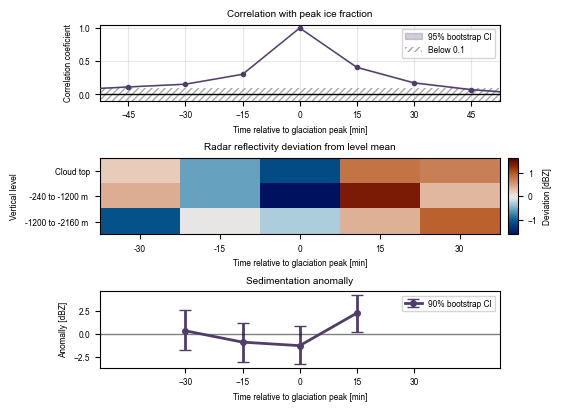

In [ ]:

# fig = plt.figure(figsize=(6.69291, 6.69291*3.504/5.501), constrained_layout=True) 170 mm
fig = plt.figure(figsize=(5.501, 4), constrained_layout=True)#5.501*3.504/5.501), constrained_layout=True)
gs = gridspec.GridSpec(3, 3,height_ratios=[1, 1,1], width_ratios=[1,1,0.05],figure=fig)#,hspace=1.2, wspace=0.3)#,
ax_heat = fig.add_subplot(gs[1, :2])
ax_top_cb = fig.add_subplot(gs[1, 2])
ax_anom = fig.add_subplot(gs[2, :2])
ax_corr = fig.add_subplot(gs[0, :2])


# Common axes formatting
for ax in (ax_heat,):
    ax.set_xticks(np.arange(len(rel_times_min)))
    ax.set_xticklabels(rel_times_min)
    ax.set_yticks(np.arange(len(level_labels)))
    ax.set_yticklabels(level_labels)
    ax.set_ylabel("Vertical level")
    ax.set_xlabel("Time relative to glaciation peak [min]")

vmax = np.nanmax(np.abs(dev_vs_others_map))



ax_heat.set_title("Radar reflectivity deviation from level mean")

im1 = ax_heat.imshow(
    dev_vs_others_map,
    aspect="auto",
    cmap=cm.vik,
    norm=TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax),
    origin="upper",
)

cbar = fig.colorbar(im1, cax=ax_top_cb)
cbar.set_label("Deviation [dBZ]")  # Adjust units/label as needed

index_times = rel_times_min[:-1]

ci_percent = 100 * confidence_level
# ax_anom
ax_anom.errorbar(
    index_times,
    sedimentation_index,
    yerr=np.vstack([
        np.maximum(
            sedimentation_index - sedimentation_index_ci_low,
            0,
        ),
        np.maximum(
            sedimentation_index_ci_high - sedimentation_index,
            0,
        ),
    ]),
    marker="o",
    linewidth=2,
    markersize=4,
    capsize=4,
    label=f"{ci_percent:g}% bootstrap CI",
    color=classifiacation_palette[4]
)

ax_anom.legend()
ax_anom.axhline(
    0,
    color="k",
    linewidth=1,
    alpha=0.5,
)

ax_anom.set_xticks(rel_times_min)
ax_anom.set_xlabel("Time relative to glaciation peak [min]")
ax_anom.set_ylabel("Anomally [dBZ]")
ax_anom.set_title("Sedimentation anomally")
ax_anom.set_xlim(-45-7.5,+45+7.5)
ax_anom.legend(loc="upper right")


ax_corr.plot(
    corr_peak_ci["rel_time_min"],
    corr_peak_ci["corr_with_peak"],
    marker="o",
    markersize=3,
    linewidth=1,
    # label="Correlation with peak",
    zorder=3,
    color=classifiacation_palette[4]
)

ax_corr.fill_between(
    corr_peak_ci["rel_time_min"],
    corr_peak_ci["ci_low"],
    corr_peak_ci["ci_high"],
    alpha=0.25,
    label="95% bootstrap CI",
    zorder=2,
    color=classifiacation_palette[4]
)

# ax_corr.axvline(
#     0,
#     color="k",
#     linestyle="--",
#     linewidth=1,
#     label="Glaciation peak",
#     zorder=4,
# )

ax_corr.axhline(
    0,
    color="k",
    linewidth=1,
    zorder=4,
)

# Hatched region: correlation below 0.1
ax_corr.axhspan(
    -0.1,
    0.1,
    facecolor="none",
    edgecolor="0.65",
    hatch="/////",
    linewidth=0,
    zorder=0,
    label="Below 0.1",
)

# Label every 15-minute sample
xmin = corr_peak_ci["rel_time_min"].min()
xmax = corr_peak_ci["rel_time_min"].max()

xticks = np.arange(
    np.floor(xmin / 15) * 15,
    np.ceil(xmax / 15) * 15 + 15,
    15,
)

ax_corr.set_xticks(xticks)
ax_corr.set_xlim(xmin, xmax)
ax_corr.set_xlim(-45-7.5,45+7.5)


ax_corr.set_xlabel("Time relative to glaciation peak [min]")
ax_corr.set_ylabel("Correlation coeficient")
ax_corr.set_title("Correlation with peak ice fraction")
ax_corr.set_ylim(-0.1, 1.05)

ax_corr.grid(alpha=0.3)
ax_corr.legend()


fig.savefig(
    "/Volumes/University_stuff/Code_Projects/MSGI/plotting/Publication_figures/Bulk_figure.pdf",
    format="pdf",
    dpi=300
)